# 2.5 — Biais, variance, validation croisée et courbe ROC en C#

**Navigation** · [Sommaire du cours](README.md) · [Version Python](2.5-Biais-Variance-CV-ROC.ipynb) · [Calibration](2.5b-Calibration-Probabilites-CSharp.ipynb) · [Analyser les erreurs](2.13-Analyse-Erreurs-CSharp.ipynb)

Vous comparerez trois classifieurs à données identiques, puis étudierez trois pièges d’évaluation. Vous apprendrez à distinguer l’écart train/test, les erreurs dues au découpage et les erreurs dues au seuil. Prérequis : train et test, classification binaire et tableau de données.

Ce carnet utilise la régression logistique L-BFGS de ML.NET et les vrais estimateurs CART, forêt et k-NN de scikit-learn. Le noyau .NET Interactive doit pouvoir charger un CPython 3.13 avec scikit-learn 1.9.1 et NumPy. Les scores sont recalculés à chaque expérience.

In [1]:
#r "nuget: Microsoft.ML,5.0.0"
#r "nuget: pythonnet,3.1.0"
#load "../../../Config/PythonNetLoader.cs"
using Microsoft.ML;
using Microsoft.ML.Data;
using Microsoft.ML.Trainers;
#nullable enable
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using System.Security;
using System.Text;
using System.Text.Json;
using Microsoft.DotNet.Interactive.Formatting;
using Python.Runtime;

CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
record MlFigure(string Markup);
Formatter.Register<MlFigure>((figure, writer) => writer.Write(figure.Markup), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(MlFigure), "image/svg+xml");
static void RequireMl(bool condition, string explanation)
{
    if (!condition)
        throw new InvalidOperationException(explanation);
}

// Le quantile linéaire NumPy correspond à une interpolation entre deux statistiques d'ordre.
static double QuantileMl(IEnumerable<double> values, double probability)
{
    var sorted = values.Order().ToArray();
    double index = probability * (sorted.Length - 1);
    int lower = (int)Math.Floor(index);
    int upper = Math.Min(lower + 1, sorted.Length - 1);
    return sorted[lower] + (index - lower) * (sorted[upper] - sorted[lower]);
}

// Le dénominateur n convient aux tirages qui constituent la distribution représentée.
static double StdMl(IReadOnlyCollection<double> values)
{
    double mean = values.Average();
    return Math.Sqrt(values.Sum(value => Math.Pow(value - mean, 2)) / values.Count);
}

// Le petit contrat JSON ne transfère que les données et résultats des appels ciblés aux estimateurs.
static T InferenceMl<T>(string program, object request)
{
    using var gil = Py.GIL();
    using var scope = Py.CreateScope();
    using var data = new PyString(JsonSerializer.Serialize(request));
    scope.Set("request_json", data);
    scope.Exec(program);
    return JsonSerializer.Deserialize<T>(scope.Get<string>("response_json")) ?? throw new InvalidOperationException("Le moteur n’a pas renvoyé de résultat.");
}

static string PyVersionMl(string package)
{
    using var gil = Py.GIL();
    using var module = Py.Import(package);
    using var version = module.GetAttr("__version__");
    return version.As<string>();
}

record MlSeries(string Name, string Color, double[] X, double[] Y, bool Scatter = false);
static void PlotMl(string title, string xLabel, string yLabel, params MlSeries[] series)
{
    // Les limites suivent les données plutôt que les résultats d'un run de référence.
    const int left = 82, top = 52, width = 660, height = 240;
    double xMin = series.SelectMany(s => s.X).Min(), xMax = series.SelectMany(s => s.X).Max();
    double yMin = series.SelectMany(s => s.Y).Min(), yMax = series.SelectMany(s => s.Y).Max();
    if (xMin == xMax)
        xMax += 1;
    if (yMin == yMax)
        yMax += 1;
    static string F(double v) => v.ToString("G5", CultureInfo.InvariantCulture);
    static string E(string v) => SecurityElement.Escape(v)!;
    double X(double v) => left + width * (v - xMin) / (xMax - xMin);
    double Y(double v) => top + height * (yMax - v) / (yMax - yMin);
    var svg = new StringBuilder();
    svg.Append($"<svg xmlns='http://www.w3.org/2000/svg' role='img' aria-label='{E(title)}' viewBox='0 0 790 410' width='790'><rect width='100%' height='100%' fill='white'/>");
    svg.Append($"<g font-family='system-ui,sans-serif' fill='#172742' font-size='13'><text x='{left}' y='28' font-size='17' font-weight='bold'>{E(title)}</text>");
    for (int tick = 0; tick <= 5; tick++)
    {
        double part = tick / 5.0, zx = left + width * part, zy = top + height * (1 - part);
        svg.Append($"<path d='M{left} {F(zy)}H{left + width}' stroke='#d9e1e8'/><text x='{left - 8}' y='{F(zy + 4)}' text-anchor='end'>{F(yMin + part * (yMax - yMin))}</text>");
        svg.Append($"<text x='{F(zx)}' y='{top + height + 20}' text-anchor='middle'>{F(xMin + part * (xMax - xMin))}</text>");
    }

    svg.Append($"<path d='M{left} {top}V{top + height}H{left + width}' stroke='#526479' fill='none'/><text x='{left + width / 2}' y='340' text-anchor='middle'>{E(xLabel)}</text><text x='22' y='175' transform='rotate(-90 22 175)' text-anchor='middle'>{E(yLabel)}</text>");
    for (int i = 0; i < series.Length; i++)
    {
        var s = series[i];
        // Conserver les points individuels pour matérialiser des observations, des mesures ou des valeurs par groupe.
        var points = s.X.Zip(s.Y, (x, y) => (X: X(x), Y: Y(y))).ToArray();
        if (!s.Scatter)
        {
            string path = string.Join(" ", points.Select(p => $"{F(p.X)},{F(p.Y)}"));
            svg.Append($"<polyline points='{path}' fill='none' stroke='{s.Color}' stroke-width='2.4'/>");
        }
        else
        {
            foreach (var point in points)
                svg.Append($"<circle cx='{F(point.X)}' cy='{F(point.Y)}' r='3.2' fill='{s.Color}'/>");
        }

        int keyX = left + i % 2 * 320, keyY = 365 + i / 2 * 20;
        svg.Append($"<rect x='{keyX}' y='{keyY - 9}' width='18' height='8' fill='{s.Color}'/><text x='{keyX + 25}' y='{keyY}'>{E(s.Name)}</text>");
    }

    svg.Append("</g></svg>");
    display(new MlFigure(svg.ToString()));
}

record MlData(double[][] X, int[] Y)
{
    // Les sous-ensembles sont construits en C# à partir d'indices, jamais par duplication de lignes.
    public MlData Select(int[] ids) => new(ids.Select(i => X[i]).ToArray(), ids.Select(i => Y[i]).ToArray());
}

record MlSplit(int[] Train, int[] Test);
record FitScores(int[] Prediction, double[] Probability, int[] TrainPrediction);
record ModelConfig(string Family, int Seed = 42, int Trees = 100, int? Depth = null, int MinimumLeaf = 1);
const string sklearnSplits = """
    import json
    import numpy as np
    from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, TimeSeriesSplit
    a = json.loads(request_json)
    y = np.asarray(a["Labels"])
    indexes = np.arange(y.size)
    if a["Kind"] == "holdout":
        train, test = train_test_split(indexes, test_size=0.30, random_state=42, stratify=y)
        folds = [(train, test)]
    elif a["Kind"] == "ordered":
        folds = TimeSeriesSplit(n_splits=a["Count"]).split(indexes)
    else:
        S = StratifiedKFold if a["Kind"] == "stratified" else KFold
        random_state = 0 if a["Shuffle"] else None
        folds = S(n_splits=a["Count"], shuffle=a["Shuffle"], random_state=random_state).split(indexes, y)
    response_json = json.dumps([{"Train": tr.tolist(), "Test": te.tolist()} for tr, te in folds])
    """;
static MlSplit[] GetSplits(int[] labels, string kind, int count = 5, bool shuffle = false)
{
    var folds = InferenceMl<MlSplit[]>(sklearnSplits, new { Labels = labels, Kind = kind, Count = count, Shuffle = shuffle });
    // Disjonction stricte, couverture et ordre causal sont des propriétés du protocole.
    foreach (var fold in folds)
        RequireMl(!fold.Train.Intersect(fold.Test).Any() && (kind != "ordered" || fold.Train.Max() < fold.Test.Min()), "Fuite entre entraînement et test.");
    if (kind != "holdout" && kind != "ordered")
        RequireMl(folds.SelectMany(f => f.Test).Order().SequenceEqual(Enumerable.Range(0, labels.Length)), "Chaque ligne doit entrer dans un seul pli de test.");
    return folds;
}

const string sklearnFit = """
    import json
    import numpy as np
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.tree import DecisionTreeClassifier
    a = json.loads(request_json)
    c = a["Config"]
    if c["Family"] == "forest":
        model = RandomForestClassifier(n_estimators=c["Trees"], max_depth=c["Depth"],
                                       min_samples_leaf=c["MinimumLeaf"], random_state=c["Seed"], n_jobs=1)
    elif c["Family"] == "tree":
        model = DecisionTreeClassifier(random_state=c["Seed"])
    else:
        raise ValueError("Famille d'estimateur appelée inconnue")
    x = np.asarray(a["Train"]["X"])
    test_x = np.asarray(a["Test"]["X"])
    model.fit(x, a["Train"]["Y"], sample_weight=a["Weights"])
    positive_col = int(np.where(model.classes_ == 1)[0][0])
    response_json = json.dumps({"Prediction": model.predict(test_x).tolist(),
                                "Probability": model.predict_proba(test_x)[:, positive_col].tolist(),
                                "TrainPrediction": model.predict(x).tolist()})
    """;
static FitScores FitTreeModel(ModelConfig config, MlData train, MlData test, double[]? weights = null)
{
    return InferenceMl<FitScores>(sklearnFit, new { Config = config, Train = train, Test = test, Weights = weights });
}

static double Accuracy(int[] expected, int[] predicted)
{
    RequireMl(expected.Length == predicted.Length && expected.Length > 0, "Étiquettes et prédictions doivent être appariées.");
    return expected.Zip(predicted, (y, p) => y == p ? 1.0 : 0.0).Average();
}

static int[, ] Confusion(int[] labels, int[] prediction)
{
    // On garde les observations en lignes et les décisions en colonnes.
    var counts = new int[2, 2];
    for (int i = 0; i < labels.Length; i++)
        counts[labels[i], prediction[i]]++;
    RequireMl(counts.Cast<int>().Sum() == labels.Length, "Une prédiction doit contribuer à une seule case.");
    return counts;
}

if (PythonNetLoader.Initialize(typeof(PythonEngine).Assembly, "sklearn")is not null)
    PythonEngine.BeginAllowThreads();
Console.WriteLine($".NET {Environment.Version} | scikit-learn {PyVersionMl("sklearn")} | NumPy {PyVersionMl("numpy")}");
class LogisticRow
{
    public bool Label { get; set; }
    public float[] Features { get; set; } = [];
}

class LogisticScore
{
    public bool PredictedLabel { get; set; }
    public float Probability { get; set; }
}

static FitScores FitLogistic(MlData train, MlData test, int iterations)
{
    var ml = new MLContext(seed: 42);
    var schema = SchemaDefinition.Create(typeof(LogisticRow));
    schema[nameof(LogisticRow.Features)].ColumnType = new VectorDataViewType(NumberDataViewType.Single, train.X[0].Length);
    IDataView View(MlData data) => ml.Data.LoadFromEnumerable(data.X.Zip(data.Y, (x, y) => new LogisticRow { Features = x.Select(v => (float)v).ToArray(), Label = y == 1 }), schema);
    var rows = View(train);
    // La mise à l'échelle s'ajuste sur chaque train/pli, puis s'applique au test par le pipeline.
    var estimator = ml.Transforms.NormalizeMeanVariance(nameof(LogisticRow.Features)).Append(ml.BinaryClassification.Trainers.LbfgsLogisticRegression(new LbfgsLogisticRegressionBinaryTrainer.Options { MaximumNumberOfIterations = iterations, L1Regularization = 0f, L2Regularization = 1f / train.Y.Length }));
    var fitted = estimator.Fit(rows);
    var holdout = ml.Data.CreateEnumerable<LogisticScore>(fitted.Transform(View(test)), reuseRowObject: false).ToArray();
    var training = ml.Data.CreateEnumerable<LogisticScore>(fitted.Transform(rows), reuseRowObject: false).ToArray();
    return new FitScores(holdout.Select(p => p.PredictedLabel ? 1 : 0).ToArray(), holdout.Select(p => (double)p.Probability).ToArray(), training.Select(p => p.PredictedLabel ? 1 : 0).ToArray());
}

static FitScores FitComparison(ModelConfig model, MlData train, MlData test, int iterations = 1000)
{
    return model.Family == "logistic" ? FitLogistic(train, test, iterations) : FitTreeModel(model, train, test);
}

static double[] ScoreFolds(ModelConfig config, MlData data, MlSplit[] folds, int iterations = 1000)
{
    // Chaque pli réajuste l'estimateur et ses transformations en isolation.
    return folds.Select(fold =>
    {
        var test = data.Select(fold.Test);
        return Accuracy(test.Y, FitComparison(config, data.Select(fold.Train), test, iterations).Prediction);
    }).ToArray();
}

static void ShowScores(string label, double[] scores)
{
    Console.WriteLine($"{label, -22} {string.Join(" / ", scores.Select(s => s.ToString("F3")))} | moyenne {scores.Average():F3} | écart-type {StdMl(scores):F3}");
}

Installing Packages Microsoft.ML pythonnet

.NET 10.0.14 | scikit-learn 1.9.1 | NumPy 2.4.4



warning CS1701: Assuming assembly reference 'System.Collections.Immutable, Version=9.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'Microsoft.ML.DataView' matches identity 'System.Collections.Immutable, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Collections.Immutable', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'Microsoft.AspNetCore.Html.Abstractions, Version=2.3.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' used by 'Microsoft.DotNet.Interactive.Formatting' matches identity 'Microsoft.AspNetCore.Html.Abstractions, Version=10.0.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' of 'Microsoft.AspNetCore.Html.Abstractions', you may need to supply runtime policy



## Avant de commencer

Un classifieur réussit 99 % des prédictions sur un jeu où 99 % des cas appartiennent à la même classe. Quelles informations lui manquent pour juger le résultat ?

<details><summary>Réponse</summary>

Une décision constante atteint déjà 99 %. Vérifiez surtout quelles erreurs le modèle fait sur la classe rare et ce qu’elles coûtent.

</details>

## 1. Le compromis biais–variance

Un modèle très contraint peut sous-ajuster et manquer de précision sur train et test. Un modèle plus souple peut mémoriser le train et perdre sur le test. Le jeu de Wisconsin contient 30 caractéristiques calculées à partir de mesures cellulaires. L’étiquette **1 indique une tumeur bénigne**, l’étiquette 0 une tumeur maligne. Gardons cette convention dans tous les calculs de confusion.

Le découpage stratifié 70/30 est fixé avant l’ajustement. Cela garde des proportions de classes comparables dans les deux ensembles.

In [2]:
const string loadWisconsin = """
    import json
    from sklearn.datasets import load_breast_cancer
    data = load_breast_cancer()
    response_json = json.dumps({"X": data.data.tolist(), "Y": data.target.tolist()})
    """;
// La classe 1 signifie bénin dans le jeu d’origine. Le découpage précède tout ajustement.
var wisconsin = InferenceMl<MlData>(loadWisconsin, new { });
var split = GetSplits(wisconsin.Y, "holdout").Single();
var training = wisconsin.Select(split.Train);
var holdout = wisconsin.Select(split.Test);
RequireMl(wisconsin.X.Length == 569 && wisconsin.X.All(x => x.Length == 30) && split.Train.Length == 398 && split.Test.Length == 171, "Dimensions Wisconsin ou découpage inattendus.");
Console.WriteLine($"Wisconsin : {wisconsin.Y.Length} × {wisconsin.X[0].Length}. Train : {training.Y.Length}, test : {holdout.Y.Length}.");
Console.WriteLine($"Classes 0=malin : {wisconsin.Y.Count(y => y == 0)}. 1=bénin : {wisconsin.Y.Count(y => y == 1)}.");

Wisconsin : 569 × 30. Train : 398, test : 171.


Classes 0=malin : 212. 1=bénin : 357.


## 2. Trois modèles, un même test

La régression logistique ajuste une frontière linéaire. Une forêt moyenne les prédictions de cent arbres ; un arbre profond peut adapter de nombreux seuils aux données. Les deux arbres viennent de scikit-learn afin de garder leurs paramètres CART. ML.NET normalise les entrées de la régression dans le pipeline ajusté sur le train. Les scores exacts de cette ligne peuvent donc différer du Python.

In [3]:
var logit = new ModelConfig("logistic");
var candidates = new[]
{
    logit,
    new ModelConfig("forest"),
    new ModelConfig("tree")
};
string[] names = ["Régression logistique", "Forêt de 100 arbres", "Arbre profond"];
var comparisons = candidates.Select(model => FitComparison(model, training, holdout)).ToArray();
var trainAccuracy = comparisons.Select(scores => Accuracy(training.Y, scores.TrainPrediction)).ToArray();
var testAccuracy = comparisons.Select(scores => Accuracy(holdout.Y, scores.Prediction)).ToArray();
// Évaluer tous les modèles sur l'ordre et les lignes strictement identiques.
for (int i = 0; i < candidates.Length; i++)
    Console.WriteLine($"{names[i], -24} | train {trainAccuracy[i]:F3} | test {testAccuracy[i]:F3} | écart {trainAccuracy[i] - testAccuracy[i]:F3}");

Régression logistique    | train 0.995 | test 0.965 | écart 0.030


Forêt de 100 arbres      | train 1.000 | test 0.936 | écart 0.064


Arbre profond            | train 1.000 | test 0.918 | écart 0.082


### Lecture du comparatif

L’arbre profond a le plus grand écart train/test dans cette exécution (0,082). Une différence élevée signale une généralisation incertaine. Les scores proches ne prouvent pas que les modèles ont la même variance. Un seul découpage donne une information partielle sur ce qui se passe quand le train change.

### Exercice 1 — Plus grand écart train/test

Retournez l’indice du modèle qui a le plus grand écart. Appuyez votre conclusion sur les scores et discutez l’incertitude d’un découpage unique.

In [4]:
static int? ModèleLePlusVariable(double[] train, double[] test)
{
    // TODO étudiant : comparer les écarts appariés.
    return null;
}

var gapIndex = ModèleLePlusVariable(trainAccuracy, testAccuracy);
if (gapIndex is int i)
{
    RequireMl(i >= 0 && i < names.Length, "Indice de modèle hors bornes.");
    Console.WriteLine($"Modèle sélectionné : {names[i]}.");
}
else
    Console.WriteLine("À compléter : indice du plus grand écart train/test.");

À compléter : indice du plus grand écart train/test.


## 3. Validation croisée à cinq plis

Chaque exemple sert exactement une fois de test. À chaque pli, on refait l’apprentissage, y compris les transformations. Moyenne et écart-type des scores renseignent sur la performance et sa variation entre plis.

In [5]:
var stratWisconsin = GetSplits(wisconsin.Y, "stratified");
var cvLogistic = ScoreFolds(logit, wisconsin, stratWisconsin);
ShowScores("Logistique 5 plis", cvLogistic);

Logistique 5 plis      0.947 / 0.947 / 0.947 / 0.974 / 0.991 | moyenne 0.961 | écart-type 0.018


### 3.1 Classe rare et stratification

On simule 200 points, dix variables dont cinq informatives et seulement 3 % de positifs. Un pli naïf peut ne contenir aucun positif. Une méthode qui ne sait pas reconnaître les positifs semblera tout de même réussir sur ce pli.

In [6]:
const string rareExamples = """
    import json
    from sklearn.datasets import make_classification
    x,y = make_classification(n_samples=200,n_features=10,n_informative=5,weights=[0.97,0.03],
                              random_state=42,flip_y=0,class_sep=1.5)
    response_json = json.dumps({"X":x.tolist(),"Y":y.tolist()})
    """;
// Les deux stratégies de validation reçoivent les mêmes six positifs.
var rare = InferenceMl<MlData>(rareExamples, new { });
var randomRare = GetSplits(rare.Y, "ordinary", shuffle: true);
var stratRare = GetSplits(rare.Y, "stratified", shuffle: true);
int Positives(MlSplit fold) => fold.Test.Count(i => rare.Y[i] == 1);
var randomCounts = randomRare.Select(Positives).ToArray();
var stratCounts = stratRare.Select(Positives).ToArray();
RequireMl(rare.Y.Sum() == 6 && randomCounts.Sum() == 6 && stratCounts.Sum() == 6, "Le témoin doit garder six positifs.");
for (int f = 0; f < 5; f++)
    Console.WriteLine($"Pli {f + 1}: positifs naïf {randomCounts[f]} | stratifié {stratCounts[f]}");
Console.WriteLine($"Plis sans positif : {randomCounts.Count(x => x == 0)} contre {stratCounts.Count(x => x == 0)}.");
ShowScores("Naïf", ScoreFolds(logit, rare, randomRare, iterations: 3000));
ShowScores("Stratifié", ScoreFolds(logit, rare, stratRare, iterations: 3000));

Pli 1: positifs naïf 3 | stratifié 1


Pli 2: positifs naïf 0 | stratifié 1


Pli 3: positifs naïf 2 | stratifié 1


Pli 4: positifs naïf 0 | stratifié 1


Pli 5: positifs naïf 1 | stratifié 2


Plis sans positif : 2 contre 0.


Naïf                   0.900 / 1.000 / 0.950 / 1.000 / 0.975 | moyenne 0.965 | écart-type 0.037


Stratifié              0.975 / 0.975 / 0.975 / 0.975 / 0.900 | moyenne 0.960 | écart-type 0.030


### Lecture des plis déséquilibrés

Le découpage naïf laisse deux plis sans positif, tandis que chaque pli stratifié contient au moins un des six positifs. Le décompte indique directement ce que le pli permet de tester. Même avec stratification, l’accuracy est surtout déterminée par la classe majoritaire. Pour un contrôle de la classe rare, inspectez aussi la confusion ou le rappel.

### 3.2 Série temporelle et fuite du futur

Les observations suivent une tendance plus un sinus lent et un bruit gaussien. On prédit la variable à partir de son index temporel avec trois plus proches voisins. Un tirage aléatoire permet d’interpoler entre observations passées et futures. Un découpage temporel impose d’extrapoler depuis le passé. Le contraste entre les deux protocoles est la mesure de la fuite.

In [7]:
const string noiseRequest = """
    import json
    import numpy as np
    response_json = json.dumps(np.random.default_rng(42).normal(0,0.3,300).tolist())
    """;
var noise = InferenceMl<double[]>(noiseRequest, new { });
double[][] times = Enumerable.Range(0, 300).Select(i => new double[] { i }).ToArray();
double[] timeSeries = noise.Select((e, i) => .02 * i + 6 * Math.Sin(i / 12.0) + e).ToArray();
const string nearestFit = """
    import json
    from sklearn.neighbors import KNeighborsRegressor
    a = json.loads(request_json)
    fitted = KNeighborsRegressor(n_neighbors=3).fit(a["TrainX"],a["TrainY"])
    response_json = json.dumps(fitted.predict(a["TestX"]).tolist())
    """;
static double ScoreTime(double[][] times, double[] y, MlSplit fold)
{
    var predicted = InferenceMl<double[]>(nearestFit, new { TrainX = fold.Train.Select(i => times[i]).ToArray(), TrainY = fold.Train.Select(i => y[i]).ToArray(), TestX = fold.Test.Select(i => times[i]).ToArray() });
    // R² compare les résidus d'un même test à sa variance de référence.
    double[] actual = fold.Test.Select(i => y[i]).ToArray();
    double mean = actual.Average();
    return 1 - actual.Zip(predicted, (a, p) => Math.Pow(a - p, 2)).Sum() / actual.Sum(a => Math.Pow(a - mean, 2));
}

var mixed = GetSplits(new int[times.Length], "ordinary", shuffle: true).Select(f => ScoreTime(times, timeSeries, f)).ToArray();
var temporal = GetSplits(new int[times.Length], "ordered").Select(f => ScoreTime(times, timeSeries, f)).ToArray();
ShowScores("R² aléatoire", mixed);
ShowScores("R² temporel", temporal);
Console.WriteLine($"Écart de R² : {mixed.Average() - temporal.Average():F3}.");

R² aléatoire           0.990 / 0.991 / 0.990 / 0.987 / 0.991 | moyenne 0.990 | écart-type 0.001


R² temporel            -0.927 / -4.474 / -1.820 / -0.826 / -4.780 | moyenne -2.566 | écart-type 1.721


Écart de R² : 3.555.


### Lecture de la fuite temporelle

Le R² moyen vaut 0,990 avec des dates mélangées et −2,566 avec un découpage temporel. Dans la première expérience, prédire une date à partir de voisines proches est une interpolation. Lorsqu’aucune observation future ne figure dans le train, le même modèle doit extrapoler. Un R² négatif est possible : les erreurs dépassent celles de la prédiction constante sur ce test.

### 3.3 Choisir le découpage selon les données

Stratifiez lorsque les classes sont rares, coupez par date pour prévoir un événement futur, et groupe par groupe lorsque plusieurs lignes appartiennent au même patient. Dans ce dernier cas, le patient est l’unité d’indépendance.

### Exercice 2 — Série de prix

Simulez ou chargez une série de prix, puis calculez l’écart de R² avec les deux découpages. Faites constater l’ordre des dates avant de commenter la fuite.

In [8]:
static double? MesurerFuiteSérie(double[][] dates, double[] prix)
{
    // TODO étudiant : réutiliser les deux découpages et le même estimateur.
    return null;
}

var fuite = MesurerFuiteSérie(times, timeSeries);
Console.WriteLine(fuite is double écart ? $"Écart mesuré : {écart:F3}" : "À compléter : faire varier le protocole à modèle fixé.");

À compléter : faire varier le protocole à modèle fixé.


### Exercice 3 — Quel split et pourquoi ?

Choisissez puis justifiez un découpage pour trois scénarios : 0,5 % de fraudes, une mesure de capteur à chaque minute, plusieurs prélèvements par patient. Nommez le biais évité dans chacun.

In [9]:
static (string Split, string Raison)? ProposerDécoupage(string scénario)
{
    // TODO étudiant : distinguer rareté, ordre et appartenance à un même groupe.
    return null;
}

foreach (string scénario in new[]
{
    "Fraude 0,5 %",
    "Capteur par minute",
    "Prélèvements répétés"
}

)
{
    var réponse = ProposerDécoupage(scénario);
    Console.WriteLine(réponse is { } r ? $"{scénario} : {r.Split} — {r.Raison}" : $"À compléter : {scénario}.");
}

À compléter : Fraude 0,5 %.


À compléter : Capteur par minute.


À compléter : Prélèvements répétés.


### Vérification — Pourquoi séparer dans le temps ?

<details><summary>Réponse</summary>

Le découpage par date empêche qu’un exemple de validation soit antérieur à des observations utilisées pour l’entraînement du même pli.

</details>

## 4. Comparer trois modèles à travers les mêmes plis

Tous les classifieurs reçoivent le même découpage en cinq plis. L’écart-type est la dispersion empirique des cinq scores. Ce n’est pas un intervalle de confiance indépendant, car les jeux d’entraînement se recouvrent.

In [10]:
var allScores = candidates.Select(c => ScoreFolds(c, wisconsin, stratWisconsin)).ToArray();
for (int i = 0; i < names.Length; i++)
    ShowScores(names[i], allScores[i]);

Régression logistique  0.947 / 0.947 / 0.947 / 0.974 / 0.991 | moyenne 0.961 | écart-type 0.018


Forêt de 100 arbres    0.921 / 0.939 / 0.982 / 0.965 / 0.973 | moyenne 0.956 | écart-type 0.023


Arbre profond          0.912 / 0.904 / 0.930 / 0.956 / 0.885 | moyenne 0.917 | écart-type 0.024


### Exercice 4 — Cinq ou dix plis

Recalculez le score de la régression logistique avec dix plis stratifiés. Comparez la moyenne, la dispersion et le coût d’apprentissage à cinq plis.

In [11]:
#nullable enable
static double[]? ÉvaluerDixPlis(MlData données, ModelConfig modèle)
{
    // TODO étudiant : produire dix scores tenus à l'écart de chaque entraînement.
    return null;
}

var dix = ÉvaluerDixPlis(wisconsin, logit);
if (dix is not null)
{
    RequireMl(dix.Length == 10 && dix.All(x => x >= 0 && x <= 1), "Il faut dix accuracies comprises entre 0 et 1.");
    ShowScores("Logistique 10 plis", dix);
}
else
    Console.WriteLine("À compléter : moyenne et dispersion sur dix plis.");

À compléter : moyenne et dispersion sur dix plis.


## 5. Faux positifs, faux négatifs et coûts

La confusion range les classes réelles en lignes et les prédictions en colonnes. Pour ce jeu, un **faux positif** est une tumeur maligne classée bénigne ; un **faux négatif** est une tumeur bénigne classée maligne. La définition découle du codage de la cible, sans quoi on inverse les coûts des décisions.

## 6. La courbe ROC et l’AUC

Pour chaque seuil de score, le rappel vaut $TP/(TP+FN)$ et le taux de faux positifs $FP/(FP+TN)$. On groupe les ex æquo avant d’avancer sur les deux axes. L’aire trapézoïdale se vérifie avec la probabilité qu’un positif reçoive un score supérieur à un négatif, en donnant un demi-point à une égalité.

Test : 107 bénignes, 64 malignes. AUC trapèzes 0.98934, AUC par paires 0.98934.


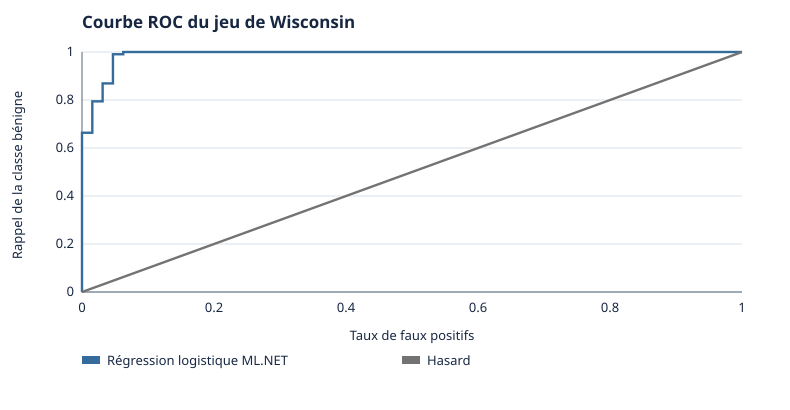

In [12]:
var probability = comparisons[0].Probability;
int classOne = holdout.Y.Count(y => y == 1), classZero = holdout.Y.Length - classOne;
var fpr = new List<double>
{
    0
};
var tpr = new List<double>
{
    0
};
int tpSeen = 0, fpSeen = 0;
foreach (var group in probability.Zip(holdout.Y).GroupBy(p => p.First).OrderByDescending(g => g.Key))
{
    // Un point à chaque seuil distinct évite de départager artificiellement les scores égaux.
    tpSeen += group.Count(p => p.Second == 1);
    fpSeen += group.Count(p => p.Second == 0);
    fpr.Add(fpSeen / (double)classZero);
    tpr.Add(tpSeen / (double)classOne);
}

double auc = 0.0;
for (int i = 1; i < fpr.Count; i++)
    auc += (fpr[i] - fpr[i - 1]) * (tpr[i] + tpr[i - 1]) / 2;
var scoresByClass = probability.Zip(holdout.Y).ToLookup(p => p.Second, p => p.First);
double rankAuc = scoresByClass[1].SelectMany(positive => scoresByClass[0].Select(negative => positive > negative ? 1.0 : positive == negative ? 0.5 : 0.0)).Average();
RequireMl(fpr.Last() == 1 && tpr.Last() == 1 && Math.Abs(auc - rankAuc) < 1e-12, "L'AUC des scores et l'oracle par paires divergent.");
Console.WriteLine($"Test : {classOne} bénignes, {classZero} malignes. AUC trapèzes {auc:F5}, AUC par paires {rankAuc:F5}.");
PlotMl("Courbe ROC du jeu de Wisconsin", "Taux de faux positifs", "Rappel de la classe bénigne", new MlSeries("Régression logistique ML.NET", "#356c9c", fpr.ToArray(), tpr.ToArray()), new MlSeries("Hasard", "#737373", [0, 1], [0, 1]));

### Lecture de la ROC

La courbe dépasse nettement la diagonale. L’aire vaut environ 0,989 avec les trapèzes et avec les paires. L’AUC décrit l’ordre des scores sur toutes les paires de classes. Elle ne dit pas si les scores sont des probabilités calibrées, ni ce que coûte une erreur. Le [carnet suivant](2.5b-Calibration-Probabilites-CSharp.ipynb) examine la calibration séparément.

### Exercice 5 — Interpréter une aire

Comparez l’aire mesurée à 0,5 et rédigez une explication en termes de paires de patients plutôt que d’accuracy.

In [13]:
#nullable enable
static string? InterpréterAuc(double aire)
{
    // TODO étudiant : comparer au hasard et expliquer l'interprétation par paires.
    return null;
}

Console.WriteLine(InterpréterAuc(auc) ?? $"À compléter : interpréter l'aire {auc:F3}.");

À compléter : interpréter l'aire 0.989.


### Vérification — Ce que mesure l’aire

<details><summary>Réponse</summary>

L’aire mesure la qualité du classement des paires positif/négatif. Elle n’est ni la proportion de décisions correctes à 0,5 ni la qualité des probabilités.

</details>

## 7. Comparer deux seuils de décision

En diminuant le seuil de 0,5 à 0,3, davantage de scores déclenchent la décision « bénin ». Cette pratique réduit ou maintient le nombre de lésions bénignes orientées vers l’alerte et augmente ou maintient le nombre de lésions malignes déclarées bénignes. Les effectifs exacts donnent le coût observé ici.

In [14]:
static int[, ] AtThreshold(double[] probabilities, int[] labels, double threshold) => Confusion(labels, probabilities.Select(p => p >= threshold ? 1 : 0).ToArray());
var at05 = AtThreshold(probability, holdout.Y, .50);
var at03 = AtThreshold(probability, holdout.Y, .30);
// L'abaissement du seuil ne peut que déplacer des décisions de 0 vers 1.
RequireMl(at03[0, 1] >= at05[0, 1] && at03[1, 0] <= at05[1, 0], "Le sens des transitions de seuil est incorrect.");
foreach (var item in new[]
{
    (Seuil: .50, C: at05),
    (Seuil: .30, C: at03)
}

)
    Console.WriteLine($"Seuil {item.Seuil:F2} | TN {item.C[0, 0]} | FP (malin classé bénin) {item.C[0, 1]} | FN (bénin classé malin) {item.C[1, 0]} | TP {item.C[1, 1]}");

Seuil 0.50 | TN 61 | FP (malin classé bénin) 3 | FN (bénin classé malin) 3 | TP 104


Seuil 0.30 | TN 60 | FP (malin classé bénin) 4 | FN (bénin classé malin) 1 | TP 106


### Lecture du choix de seuil

Abaisser le seuil ramène les bénignes classées malignes de trois à une et fait passer les malignes classées bénignes de trois à quatre. Cette variation change le coût des deux types d’erreurs. Ce sont des mouvements différents le long de la même courbe ROC. Une décision réelle doit aussi considérer les coûts et la calibration sur une population cible.

## Synthèse — Quelle métrique et quel modèle ?

Les scores par pli complètent la comparaison train/test. Les points représentent les moyennes et les bornes autour d’elles indiquent un écart-type empirique.

Indices : 1 régression logistique, 2 forêt, 3 arbre.


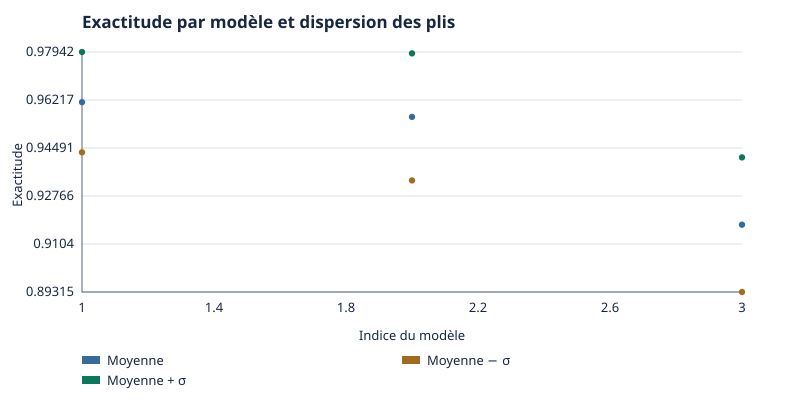

In [15]:
double[] modelPosition = [1, 2, 3];
double[] averages = allScores.Select(x => x.Average()).ToArray(), stdev = allScores.Select(StdMl).ToArray();
// Les écarts-types sont à interpréter comme dispersions observées des scores de cinq plis.
Console.WriteLine("Indices : 1 régression logistique, 2 forêt, 3 arbre.");
PlotMl("Exactitude par modèle et dispersion des plis", "Indice du modèle", "Exactitude", new MlSeries("Moyenne", "#356c9c", modelPosition, averages, true), new MlSeries("Moyenne − σ", "#a16b20", modelPosition, averages.Zip(stdev, (m, s) => m - s).ToArray(), true), new MlSeries("Moyenne + σ", "#08795c", modelPosition, averages.Zip(stdev, (m, s) => m + s).ToArray(), true));

### Exercice 6 — Courbes d’apprentissage

Pour la logistique et l’arbre, mesurez les scores train et validation sur cinq plis avec dix proportions d’entraînement de 10 à 100 %. Conservez un test fixe à l’intérieur du pli pendant que vous augmentez le train. Distinguez plateau bas et écart persistant.

In [16]:
static (double[] Train, double[] Validation)? CourbeApprentissage(MlData d, ModelConfig modèle, MlSplit[] plis, double[] fractions)
{
    // TODO étudiant : agréger un résultat par fraction de train pour chacun des deux scores.
    return null;
}

double[] fractions = Enumerable.Range(1, 10).Select(i => i / 10.0).ToArray();
foreach (var modèle in new[]
{
    logit,
    candidates[2]
}

)
{
    var curve = CourbeApprentissage(wisconsin, modèle, stratWisconsin, fractions);
    if (curve is { } c)
    {
        RequireMl(c.Train.Length == 10 && c.Validation.Length == 10, "Un point par fraction est attendu.");
        PlotMl("Courbe d'apprentissage — " + modèle.Family, "Fraction train", "Exactitude", new MlSeries("Train", "#356c9c", fractions, c.Train), new MlSeries("Validation", "#08795c", fractions, c.Validation));
    }
    else
        Console.WriteLine($"À compléter : courbe d'apprentissage du modèle {modèle.Family}.");
}

À compléter : courbe d'apprentissage du modèle logistic.


À compléter : courbe d'apprentissage du modèle tree.


## À retenir

- Un écart train/test dépend du modèle et du découpage. Refaites l’ajustement à chaque pli.
- Classe rare, autocorrélation et répétitions par patient demandent des découpages différents.
- L’AUC évalue le classement. Le seuil de décision dépend des coûts et de la population, pas de l’aire seule.

## Vérifiez votre compréhension

**Que donne la ROC pour choisir un seuil ?**

<details><summary>Réponse</summary>

L’ensemble des compromis entre rappel et faux positifs. Le contexte métier permet de choisir un point de fonctionnement.

</details>

## Pour aller plus loin

- [Documentation ML.NET de la régression logistique L-BFGS](https://learn.microsoft.com/dotnet/api/microsoft.ml.trainers.lbfgslogisticregressionbinarytrainer).
- [Validation croisée scikit-learn](https://scikit-learn.org/stable/modules/cross_validation.html).
- [Analyse d’erreurs et diagnostic par tranches](2.13-Analyse-Erreurs-CSharp.ipynb).